# 01 · Exploration des données moteurs (C-MAPSS FD001)

**Projet :** maintenance prédictive et optimisation des stocks de pièces pour une flotte de turboréacteurs.

**Question de ce notebook :** est-ce que les capteurs moteurs contiennent un signal d'usure exploitable pour anticiper les pannes ?

Si la réponse est non, inutile d'aller plus loin. Si c'est oui, on sait quels capteurs garder et quelle cible donner au modèle.

| Élément | Ce qu'on a |
|---|---|
| Source | NASA Ames, C-MAPSS, sous-jeu FD001 (Saxena et al., 2008 [1]) |
| Flotte | 100 moteurs suivis jusqu'à la panne (train) + 100 moteurs coupés avant la panne (test) |
| Granularité | 1 ligne = 1 moteur × 1 vol (cycle) |
| Panne étudiée | Dégradation du compresseur haute pression (HPC) |
| Conditions | Une seule condition de vol (niveau de la mer) |

> **Pourquoi commencer par FD001 ?** C'est le cas le plus simple : une seule condition de vol, un seul mode de panne. On valide la méthode ici, puis on la réapplique sur FD004 (6 conditions, 2 pannes), plus proche de la vraie vie.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Permet d'importer src/ depuis le dossier notebooks/
sys.path.append(str(Path.cwd().parent))
from src.data_loader import (
    FIG_DIR,
    POWERBI_DIR,
    PROCESSED_DIR,
    SENSOR_LABELS,
    SENSORS,
    SETTINGS,
    load_test,
    load_train,
)

for d in (FIG_DIR, POWERBI_DIR, PROCESSED_DIR):
    d.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110
pd.set_option("display.max_columns", 40)

## 1. Chargement et premier coup d'œil

In [2]:
train = load_train("FD001")
test = load_test("FD001")

print(f"Train : {train.shape[0]:,} lignes, {train['unit'].nunique()} moteurs")
print(f"Test  : {test.shape[0]:,} lignes, {test['unit'].nunique()} moteurs")
train.head()

Train : 20,631 lignes, 100 moteurs
Test  : 13,096 lignes, 100 moteurs


,unit,cycle,setting_1,setting_2,setting_3,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,s11,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21,RUL
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,21.61,554.36,2388.06,9046.19,1.3,47.47,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,21.61,553.75,2388.04,9044.07,1.3,47.49,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,21.61,554.26,2388.08,9052.94,1.3,47.27,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,21.61,554.45,2388.11,9049.48,1.3,47.13,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,21.61,554.00,2388.06,9055.15,1.3,47.28,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


## 2. Qualité des données

Avant toute analyse, on vérifie trois choses : valeurs manquantes, doublons, et cohérence des cycles (chaque moteur doit avoir des vols numérotés 1, 2, 3… sans trou).

In [3]:
print("Valeurs manquantes :", int(train.isna().sum().sum()))
print("Doublons (moteur, cycle) :", int(train.duplicated(["unit", "cycle"]).sum()))

trous = train.groupby("unit")["cycle"].apply(lambda c: (c.diff().dropna() != 1).sum()).sum()
print("Trous dans la numérotation des vols :", int(trous))

Valeurs manquantes : 0
Doublons (moteur, cycle) : 0
Trous dans la numérotation des vols : 0


> **Lecture :** données propres, aucun nettoyage nécessaire. C'est normal, c'est une simulation. Sur des données réelles (ACARS, carnets de maintenance), cette étape prend souvent la moitié du temps du projet.

## 3. Combien de vols tient un moteur avant la panne ?

C'est la première info utile pour un décideur : la durée de vie moyenne, mais surtout la **dispersion**. Si tous les moteurs tombaient en panne au vol 200, une maintenance à date fixe suffirait et on n'aurait pas besoin de machine learning.

count    100.0
mean     206.3
std       46.3
min      128.0
25%      177.0
50%      199.0
75%      229.2
max      362.0
Name: cycle, dtype: float64


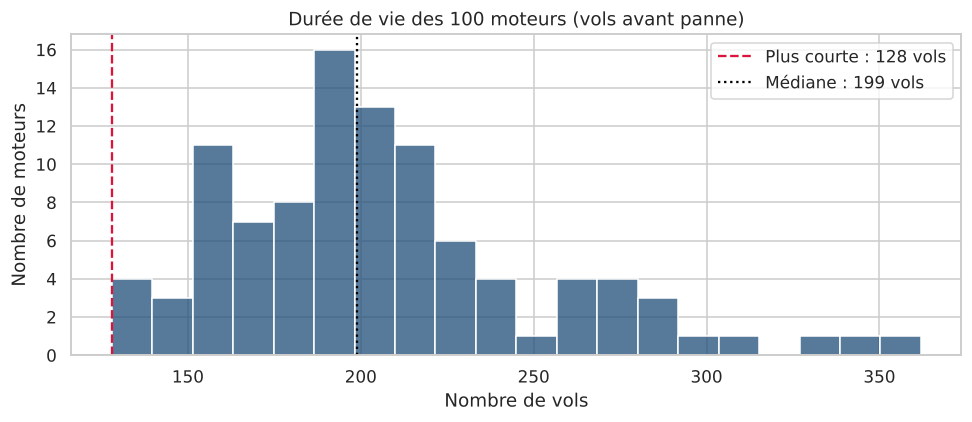

In [4]:
duree_vie = train.groupby("unit")["cycle"].max()
print(duree_vie.describe().round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(duree_vie, bins=20, ax=ax, color="#1f4e79")
ax.axvline(duree_vie.min(), color="crimson", ls="--", label=f"Plus courte : {duree_vie.min()} vols")
ax.axvline(
    duree_vie.median(), color="black", ls=":", label=f"Médiane : {duree_vie.median():.0f} vols"
)
ax.set(
    title="Durée de vie des 100 moteurs (vols avant panne)",
    xlabel="Nombre de vols",
    ylabel="Nombre de moteurs",
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "01_duree_vie.png")
plt.show()

> **Pour le décideur :** les moteurs tiennent entre 128 et 362 vols, du simple au triple. Avec une maintenance à intervalle fixe, deux options aussi mauvaises l'une que l'autre (chiffrées juste en dessous) :
> - on fixe l'intervalle sur le moteur le plus fragile (128 vols) → zéro panne, mais on jette en moyenne **un tiers de la vie utile** des moteurs : pièces et heures de main-d'œuvre gaspillées ;
> - on le fixe sur la médiane (~200 vols) → peu de vie gaspillée, mais **la moitié de la flotte tombe en panne avant** : AOG (avion cloué au sol), le scénario le plus coûteux.
>
> C'est exactement cette dispersion qui justifie une approche prédictive, moteur par moteur.

In [5]:
# Chiffrage rapide de l'argument ci-dessus
for seuil in [duree_vie.min(), duree_vie.median()]:
    pannes_avant = (duree_vie < seuil).mean() * 100
    vie_gaspillee = (1 - seuil / duree_vie).clip(lower=0).mean() * 100
    print(
        f"Intervalle fixe à {seuil:.0f} vols -> {pannes_avant:4.0f} % de moteurs en panne avant, "
        f"{vie_gaspillee:4.0f} % de vie moyenne jetée"
    )

Intervalle fixe à 128 vols ->    0 % de moteurs en panne avant,   35 % de vie moyenne jetée
Intervalle fixe à 199 vols ->   49 % de moteurs en panne avant,    8 % de vie moyenne jetée


## 4. Quels capteurs servent à quelque chose ?

Un capteur qui ne bouge jamais ne peut pas annoncer une panne. On regarde l'écart-type de chaque capteur : s'il est quasi nul, on l'écarte.

In [6]:
variabilite = train[SETTINGS + SENSORS].std().sort_values()
constants = variabilite[variabilite < 1e-4].index.tolist()
print("Colonnes quasi constantes (à écarter) :", constants)
variabilite.to_frame("ecart_type").T.round(4)

Colonnes quasi constantes (à écarter) : ['s1', 'setting_3', 's10', 's19', 's18', 's16', 's5']


,s1,setting_3,s10,s19,s18,s16,s5,setting_2,s6,setting_1,s15,s8,s13,s21,s20,s11,s2,s12,s7,s17,s3,s4,s14,s9
ecart_type,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0003,0.0014,0.0022,0.0375,0.071,0.0719,0.1083,0.1807,0.2671,0.5001,0.7376,0.8851,1.5488,6.1311,9.0006,19.0762,22.0829


> **Choix :** on retire ces colonnes. Elles sont constantes parce que FD001 n'a qu'une condition de vol : les réglages et les consignes ne varient pas. **Attention, ce ne sera plus vrai sur FD004**, où il faudra au contraire s'en servir pour normaliser par régime de vol.

## 5. Le signal d'usure est-il visible ?

On trace chaque capteur restant **en fonction du nombre de vols restants avant la panne** (RUL), pour 10 moteurs. Si l'usure se lit dans les données, les courbes doivent dériver quand on s'approche de 0.

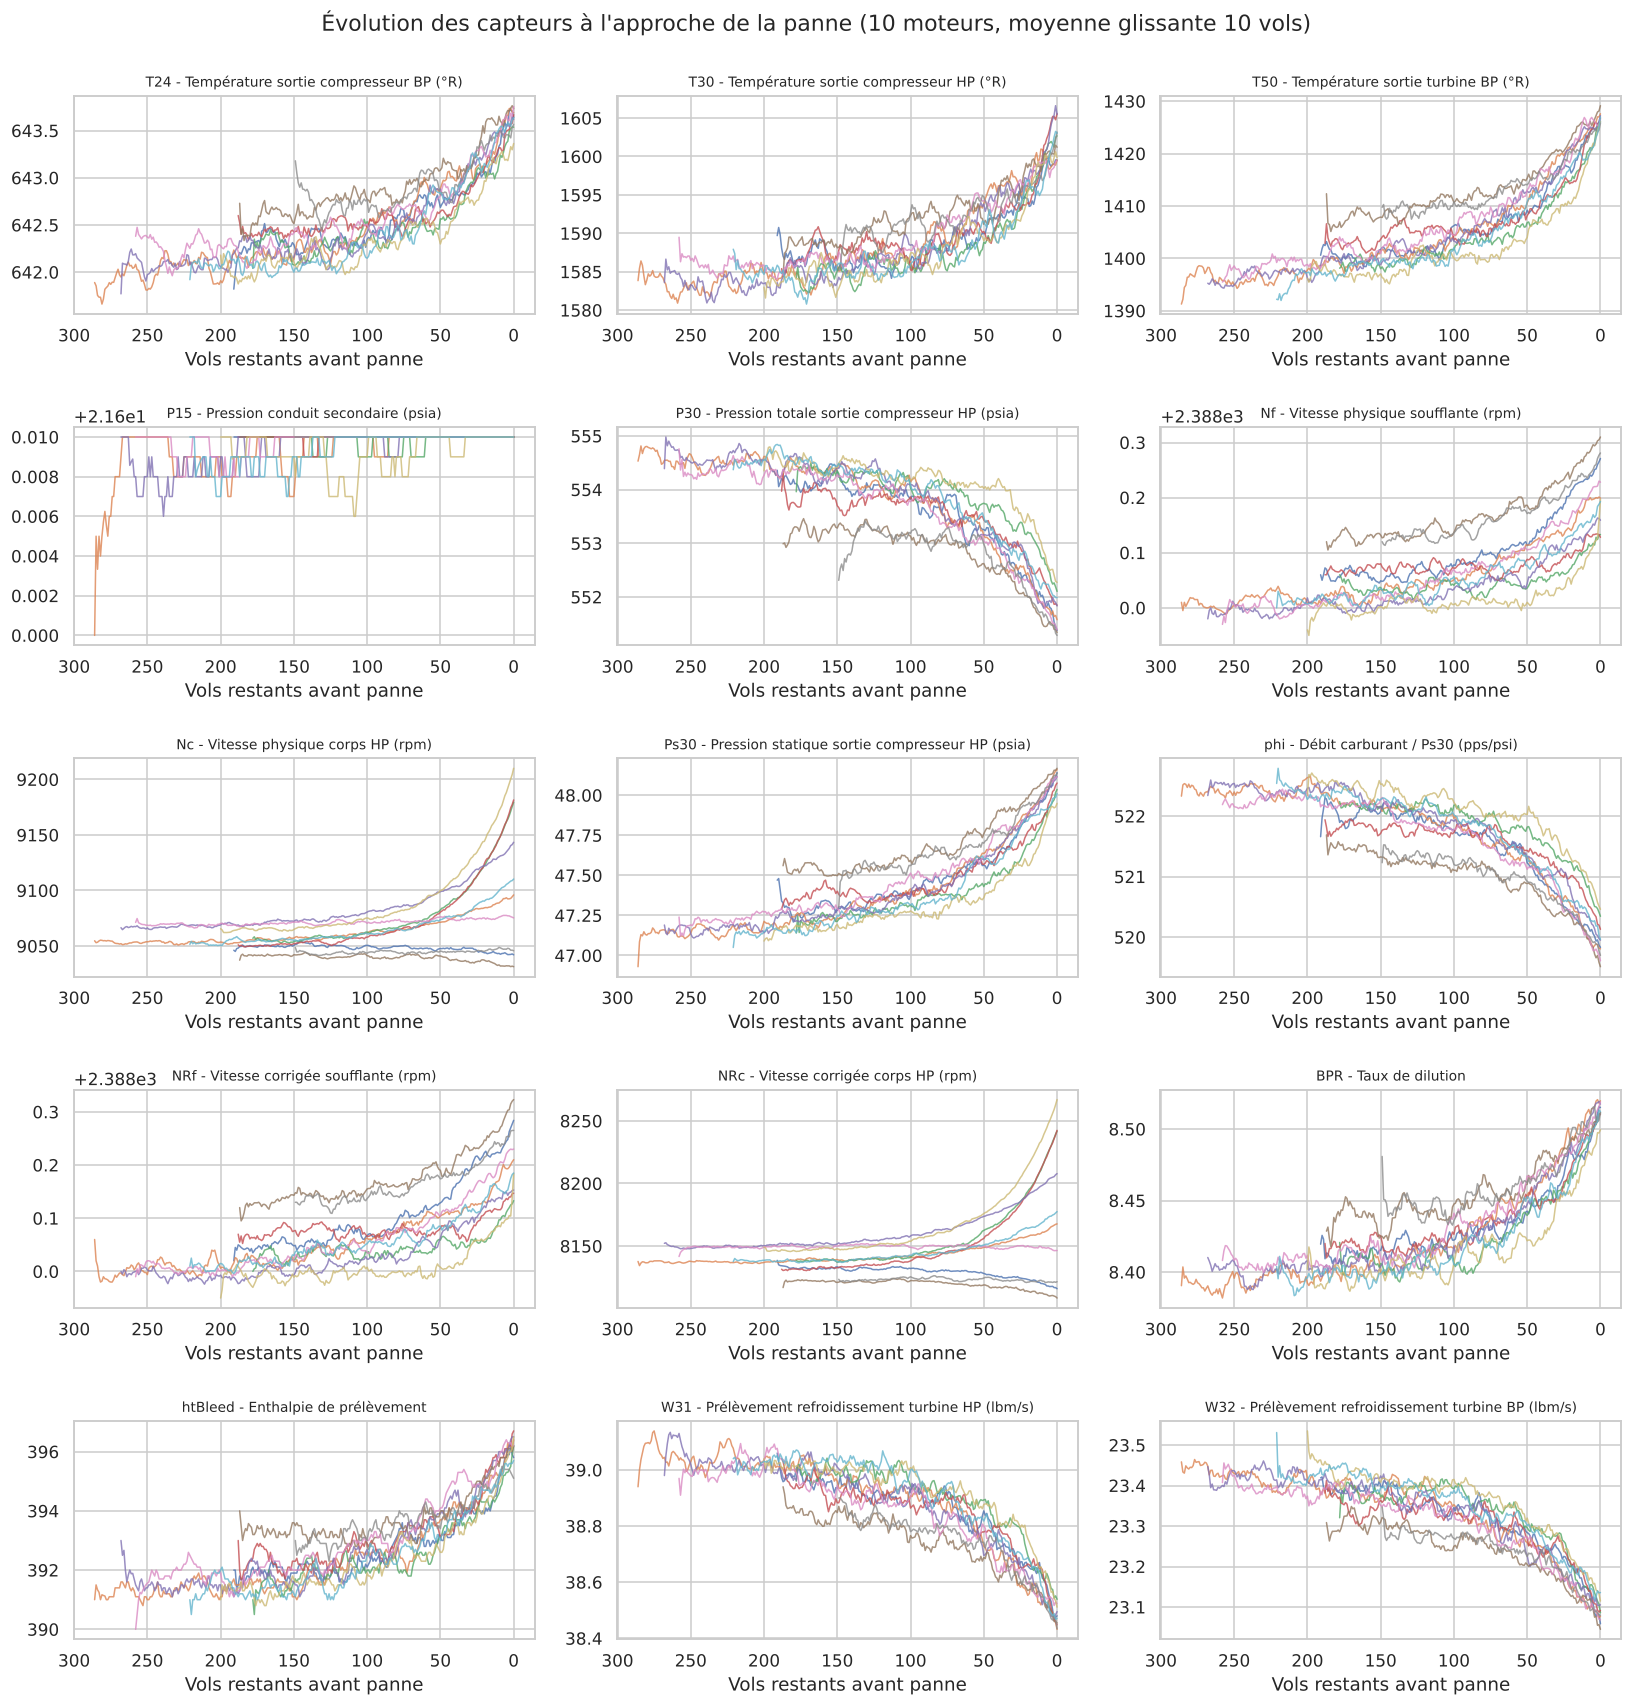

In [7]:
capteurs_utiles = [s for s in SENSORS if s not in constants]
moteurs_exemple = train["unit"].unique()[:10]

fig, axes = plt.subplots(
    len(capteurs_utiles) // 3 + 1, 3, figsize=(15, 3 * (len(capteurs_utiles) // 3 + 1))
)
for ax, s in zip(axes.flat, capteurs_utiles, strict=False):
    for u in moteurs_exemple:
        d = train[train["unit"] == u]
        lisse = d[s].rolling(10, min_periods=1).mean()  # lissage : voir note ci-dessous
        ax.plot(d["RUL"], lisse, lw=1, alpha=0.8)
    ax.invert_xaxis()  # la panne (RUL = 0) à droite
    ax.set_title(SENSOR_LABELS[s], fontsize=9)
    ax.set_xlabel("Vols restants avant panne")
for ax in axes.flat[len(capteurs_utiles) :]:
    ax.remove()
plt.suptitle(
    "Évolution des capteurs à l'approche de la panne (10 moteurs, moyenne glissante 10 vols)", y=1.0
)
plt.tight_layout()
plt.savefig(FIG_DIR / "02_capteurs_vs_rul.png", bbox_inches="tight")
plt.show()

> **Pourquoi lisser ?** Dans la simulation, la maintenance courante entre deux vols est modélisée comme du bruit, auquel s'ajoute un bruit de mesure capteur [1]. Un vol isolé peut donc faire croire que le moteur « s'améliore ». Seule la tendance sur plusieurs vols a du sens.
>
> **Lecture :** oui, le signal est là. Pour la plupart des capteurs, les courbes sont plates pendant la première partie de la vie, puis dérivent nettement dans les ~100 derniers vols : températures en sortie de compresseur et de turbine qui montent, pression totale en sortie de compresseur HP (P30) qui baisse, débits de refroidissement turbine (W31, W32) qui baissent. C'est cohérent avec la physique : un compresseur HP usé comprime moins bien et chauffe plus pour fournir la même poussée.
>
> Deux capteurs (`s9` vitesse corps HP, `s14` vitesse corrigée corps HP) se comportent différemment d'un moteur à l'autre : certains montent, d'autres descendent. Ils seront moins fiables. Quant à `s6` (P15), il ne fait que sauter entre deux valeurs : c'est du bruit d'arrondi, pas de l'usure.

## 6. Classement des capteurs par lien avec l'usure

On quantifie ce qu'on voit à l'œil avec la corrélation de Spearman entre chaque capteur et la RUL (Spearman plutôt que Pearson car la relation n'est pas linéaire : plate puis qui plonge).

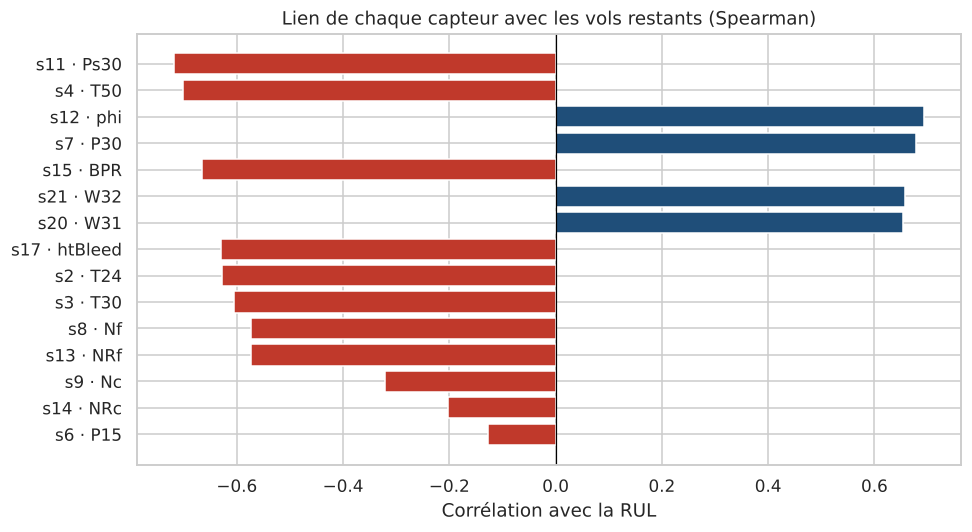

,spearman_vs_RUL
s11,-0.718
s4,-0.702
s12,0.693
s7,0.679
s15,-0.666
s21,0.657
s20,0.653
s17,-0.629
s2,-0.629
s3,-0.606


In [8]:
corr = (
    train[capteurs_utiles + ["RUL"]]
    .corr(method="spearman")["RUL"]
    .drop("RUL")
    .sort_values(key=abs, ascending=False)
)

fig, ax = plt.subplots(figsize=(9, 5))
couleurs = ["#c0392b" if v < 0 else "#1f4e79" for v in corr.values]
ax.barh(
    [f"{s} · {SENSOR_LABELS[s].split(' - ')[0]}" for s in corr.index], corr.values, color=couleurs
)
ax.axvline(0, color="black", lw=0.8)
ax.invert_yaxis()
ax.set(
    title="Lien de chaque capteur avec les vols restants (Spearman)",
    xlabel="Corrélation avec la RUL",
)
plt.tight_layout()
plt.savefig(FIG_DIR / "03_correlation_rul.png")
plt.show()
corr.round(3).to_frame("spearman_vs_RUL")

In [9]:
SEUIL = 0.5
capteurs_retenus = corr[corr.abs() >= SEUIL].index.tolist()
print(f"Capteurs retenus (|corrélation| >= {SEUIL}) : {capteurs_retenus}")

Capteurs retenus (|corrélation| >= 0.5) : ['s11', 's4', 's12', 's7', 's15', 's21', 's20', 's17', 's2', 's3', 's8', 's13']


> **Choix :** seuil à 0,5 en valeur absolue. Résultat : **12 capteurs retenus**, et on écarte logiquement `s9`, `s14` (comportement incohérent d'un moteur à l'autre) et `s6` (bruit). Il est volontairement simple et explicable ; le modèle du notebook 02 nous dira si on perd de l'information (on testera avec et sans les capteurs écartés).
>
> **Point de vigilance :** certains capteurs retenus sont très corrélés entre eux (ils mesurent la même usure sous deux angles). Ce n'est pas un problème pour un modèle à base d'arbres, mais il faudra en tenir compte si on veut interpréter des coefficients.

**Contrôle croisé avec la littérature.** Ramasso & Saxena (2014) [3] relèvent que le sous-ensemble de capteurs le plus utilisé est celui du gagnant du challenge PHM'08 (Wang et al., 2008 [5]). Attention : ils le numérotent **par colonne du fichier** (7, 8, 9, 12, 16, 17, 20). Les 5 premières colonnes étant moteur, cycle et 3 réglages, ça correspond aux capteurs s2, s3, s4, s7, s11, s12, s15.

In [10]:
colonnes_litterature = [7, 8, 9, 12, 16, 17, 20]
capteurs_litterature = [f"s{c - 5}" for c in colonnes_litterature]  # colonne n -> capteur n-5
communs = [c for c in capteurs_litterature if c in capteurs_retenus]
print("Sélection de la littérature :", capteurs_litterature)
print(f"Présents dans notre sélection : {len(communs)}/{len(capteurs_litterature)}")
print(
    "Capteurs en plus chez nous   :", [c for c in capteurs_retenus if c not in capteurs_litterature]
)

Sélection de la littérature : ['s2', 's3', 's4', 's7', 's11', 's12', 's15']
Présents dans notre sélection : 7/7
Capteurs en plus chez nous   : ['s21', 's20', 's17', 's8', 's13']


> **Lecture :** notre sélection, obtenue indépendamment par la corrélation, contient les 7 capteurs de la littérature, plus 5 autres. Bon signe de cohérence. Dans le notebook 02, on comparera les deux sélections : si les 5 capteurs supplémentaires n'améliorent pas l'erreur, on prendra la sélection courte, plus simple à expliquer.

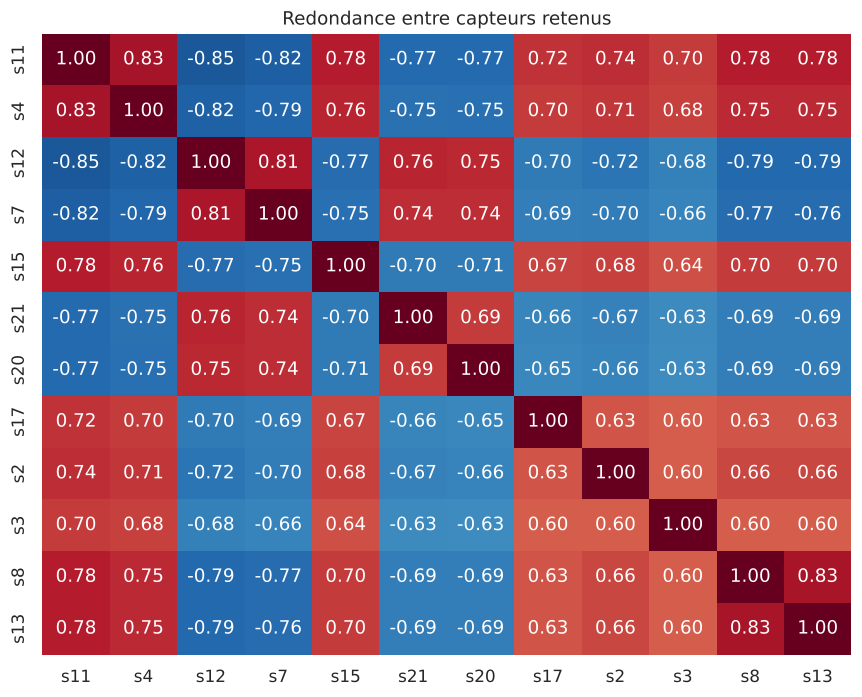

In [11]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(
    train[capteurs_retenus].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    ax=ax,
    cbar=False,
)
ax.set_title("Redondance entre capteurs retenus")
plt.tight_layout()
plt.savefig(FIG_DIR / "04_redondance_capteurs.png")
plt.show()

## 7. Quelle cible donner au modèle ?

Problème : en début de vie, un moteur à 300 vols de la panne et un autre à 200 vols ont **exactement les mêmes mesures** (courbes plates). Demander au modèle de les distinguer, c'est lui demander l'impossible : il va apprendre du bruit.

**Solution standard : plafonner la RUL** (principe popularisé par Heimes, 2008 [4]). C'est cohérent avec la façon dont les données ont été générées : Saxena et al. (2008) [1] imposent une usure **exponentielle**, quasi invisible au début puis qui s'accélère. Tant qu'un moteur est "sain", on dit simplement qu'il lui reste "au moins N vols". Le modèle n'apprend à être précis que quand ça compte, c'est-à-dire près de la panne.

Pour choisir N, on regarde à partir de combien de vols restants les capteurs commencent à bouger.

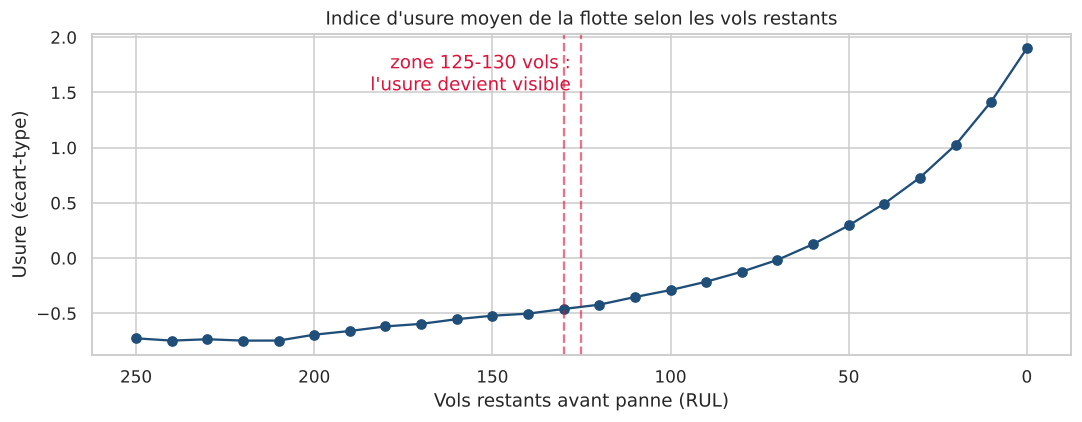

In [12]:
# Moyenne de chaque capteur retenu (standardisé) par tranche de RUL, sur toute la flotte
z = train[capteurs_retenus].apply(lambda c: (c - c.mean()) / c.std())
z["RUL_bin"] = (train["RUL"] // 10) * 10
profil = z.groupby("RUL_bin")[capteurs_retenus].mean().loc[:250]

# Indice de santé simple = moyenne des capteurs orientés dans le même sens
orient = np.sign(corr[capteurs_retenus])
sante = (profil * -orient).mean(axis=1)  # monte quand l'usure augmente

fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(sante.index, sante.values, marker="o", color="#1f4e79")
for n in (125, 130):
    ax.axvline(n, color="crimson", ls="--", alpha=0.6)
ax.text(
    128,
    sante.max() * 0.8,
    "zone 125-130 vols :\nl'usure devient visible",
    color="crimson",
    ha="right",
)
ax.invert_xaxis()
ax.set(
    title="Indice d'usure moyen de la flotte selon les vols restants",
    xlabel="Vols restants avant panne (RUL)",
    ylabel="Usure (écart-type)",
)
plt.tight_layout()
plt.savefig(FIG_DIR / "05_choix_plafond_rul.png")
plt.show()

> **Choix :** plafond à **125 vols**. Au-delà, l'indice d'usure bouge à peine (il gagne moins de 0,3 écart-type entre 250 et 125 vols restants) ; en dessous, la pente s'accélère franchement. Autrement dit, au-delà de 125 vols, un moteur "a l'air neuf". C'est aussi la valeur retenue par une grande partie de la littérature, dont Li et al. (2018) [6] (Heimes utilisait 130), ce qui nous permettra de comparer nos résultats.
>
> **Traduction métier :** le modèle répondra "ce moteur a encore plus de 125 vols devant lui, rien à faire" ou "il lui reste environ 40 vols, planifier la dépose". C'est exactement le niveau de précision dont la logistique a besoin.

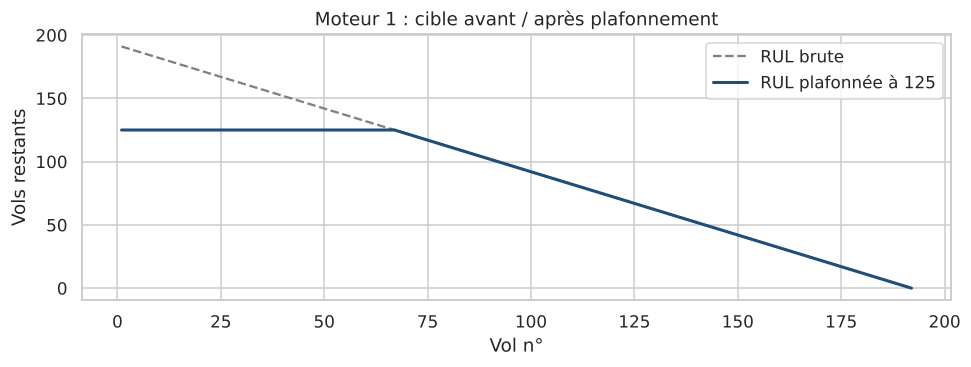

In [13]:
RUL_PLAFOND = 125
train["RUL_cap"] = train["RUL"].clip(upper=RUL_PLAFOND)
test["RUL_cap"] = test["RUL"].clip(upper=RUL_PLAFOND)

u = 1
d = train[train["unit"] == u]
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.plot(d["cycle"], d["RUL"], label="RUL brute", ls="--", color="grey")
ax.plot(d["cycle"], d["RUL_cap"], label=f"RUL plafonnée à {RUL_PLAFOND}", color="#1f4e79", lw=2)
ax.set(
    title=f"Moteur {u} : cible avant / après plafonnement", xlabel="Vol n°", ylabel="Vols restants"
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "06_cible_plafonnee.png")
plt.show()

## 8. Le jeu de test ressemble-t-il à la vraie vie ?

Dans le test, les moteurs sont arrêtés **avant** la panne, à un moment aléatoire. C'est la situation réelle : aujourd'hui, on observe une flotte en service et on doit dire à chaque moteur combien il lui reste.

       vols_observes  rul_reelle
count          100.0       100.0
mean           131.0        75.5
std             53.6        41.8
min             31.0         7.0
25%             88.8        32.8
50%            133.5        86.0
75%            164.2       112.2
max            303.0       145.0


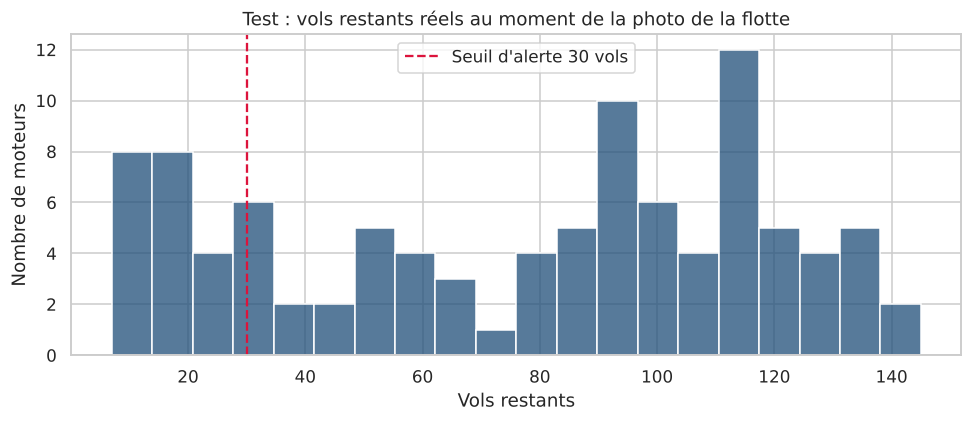

Moteurs à moins de 30 vols de la panne : 25 / 100


In [14]:
fin_test = test.groupby("unit").agg(vols_observes=("cycle", "max"), rul_reelle=("RUL", "min"))
print(fin_test.describe().round(1))

fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(fin_test["rul_reelle"], bins=20, color="#1f4e79", ax=ax)
ax.axvline(30, color="crimson", ls="--", label="Seuil d'alerte 30 vols")
ax.set(
    title="Test : vols restants réels au moment de la photo de la flotte",
    xlabel="Vols restants",
    ylabel="Nombre de moteurs",
)
ax.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "07_test_rul_reelle.png")
plt.show()
print(
    f"Moteurs à moins de 30 vols de la panne : {(fin_test['rul_reelle'] <= 30).sum()} / {len(fin_test)}"
)

> **Lecture :** la "photo" de la flotte test montre des moteurs à tous les stades d'usure, dont une partie en zone critique. C'est sur eux qu'on jugera vraiment le modèle : se tromper de 20 vols sur un moteur neuf n'a aucun impact, se tromper de 20 vols sur un moteur à 15 vols de la panne, si.

## 9. Sauvegarde pour la suite

- `data/processed/` : données préparées pour le notebook 02 (modélisation).
- `outputs/powerbi/` : premières tables pour Power BI, déjà au format **schéma en étoile** (une table de dimension moteurs + une table de faits par vol). On les complétera avec les prédictions et les stocks.

In [15]:
cols = ["unit", "cycle"] + capteurs_retenus + ["RUL", "RUL_cap"]
train[cols].to_csv(PROCESSED_DIR / "train_FD001.csv", index=False)
test[cols].to_csv(PROCESSED_DIR / "test_FD001.csv", index=False)
pd.Series(capteurs_retenus, name="capteur").to_csv(
    PROCESSED_DIR / "capteurs_retenus.csv", index=False
)

# --- Tables Power BI ---
dim_moteur = pd.concat(
    [
        train.groupby("unit")["cycle"]
        .max()
        .rename("vols_observes")
        .to_frame()
        .assign(jeu="train", statut="Panne observée"),
        fin_test[["vols_observes"]].assign(jeu="test", statut="En service"),
    ]
).reset_index()
dim_moteur["id_moteur"] = (
    dim_moteur["jeu"].str.upper() + "-" + dim_moteur["unit"].astype(str).str.zfill(3)
)
dim_moteur["sous_jeu"] = "FD001"
dim_moteur = dim_moteur[["id_moteur", "sous_jeu", "jeu", "unit", "vols_observes", "statut"]]

fact_vols = pd.concat([train.assign(jeu="train"), test.assign(jeu="test")])
fact_vols["id_moteur"] = (
    fact_vols["jeu"].str.upper() + "-" + fact_vols["unit"].astype(str).str.zfill(3)
)
fact_vols = fact_vols[["id_moteur", "cycle"] + capteurs_retenus + ["RUL", "RUL_cap"]]

dim_capteur = pd.DataFrame(
    {
        "capteur": capteurs_retenus,
        "libelle": [SENSOR_LABELS[s] for s in capteurs_retenus],
        "correlation_rul": corr[capteurs_retenus].round(3).values,
    }
)

dim_moteur.to_csv(POWERBI_DIR / "dim_moteur.csv", index=False, sep=";", decimal=",")
fact_vols.to_csv(POWERBI_DIR / "fact_vols.csv", index=False, sep=";", decimal=",")
dim_capteur.to_csv(POWERBI_DIR / "dim_capteur.csv", index=False, sep=";", decimal=",")
print({f.name: len(pd.read_csv(f, sep=";")) for f in POWERBI_DIR.glob("*.csv")})

{'dim_moteur.csv': 200, 'fact_sensibilite.csv': 4, 'fact_strategies.csv': 3, 'fact_vols.csv': 33727, 'fact_marge.csv': 6, 'fact_predictions.csv': 100, 'fact_stock_journal.csv': 1460, 'fact_stock_politiques.csv': 8, 'dim_capteur.csv': 12, 'fact_alertes.csv': 100}


> Les CSV Power BI sont exportés avec `;` et la virgule décimale pour s'ouvrir proprement dans un Power BI ou un Excel en français.

## Synthèse pour le décideur

1. **Les données sont exploitables.** 12 capteurs sur 21 portent un signal d'usure net et cohérent avec la physique (compresseur HP qui chauffe et perd en pression).
2. **La maintenance à intervalle fixe coûte cher sur cette flotte** : soit on jette un tiers de la vie utile, soit on laisse la moitié des moteurs tomber en panne. La durée de vie varie du simple au triple d'un moteur à l'autre.
3. **L'usure n'est vraiment détectable que dans les ~125 derniers vols.** Le modèle sera donc précis là où ça compte, et dira simplement "RAS" pour les moteurs sains.

**Étape suivante (notebook 02) :** entraîner le modèle de prédiction des vols restants, mesurer son erreur en vols **et avec le score asymétrique officiel du challenge** (une prédiction tardive est plus pénalisée qu'une prédiction précoce [1]), puis le comparer à la maintenance à intervalle fixe.

*Les numéros entre crochets renvoient à `docs/contexte_et_references.md`.*